In [1]:
import numpy as np

print("NumPy:", np.__version__)

NumPy: 2.5.2


In [2]:
import pandas as pd

print("Pandas:", pd.__version__)

Pandas: 3.0.5


In [3]:
import matplotlib.pyplot as plt
# print("Matplotlib:", matplotlib.__version__)

In [4]:
import seaborn as sns

print("Seaborn:", sns.__version__)

Seaborn: 0.13.2


In [5]:
from ucimlrepo import fetch_ucirepo

# Load the UCI Heart Disease dataset
heart_disease = fetch_ucirepo(id=45)

# Separate features and target
X = heart_disease.data.features
y = heart_disease.data.targets

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0



Target:


,num
0,0
1,2
2,1
3,0
4,0



Feature shape: (303, 13)
Target shape: (303, 1)


In [6]:
print("Target column:")
print(y.columns)

print("\nUnique target values:")
print(y.iloc[:, 0].unique())

print("\nTarget value counts:")
print(y.iloc[:, 0].value_counts().sort_index())

Target column:
Index(['num'], dtype='str')

Unique target values:
[0 2 1 3 4]

Target value counts:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [7]:
print("Feature names:")
print(X.columns.tolist())

print("\nData types:")
print(X.dtypes)

print("\nMissing values:")
print(X.isnull().sum())

Feature names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
dtype: object

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64


In [8]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [9]:

## age          Age in years	                    Numerical
## sex          Sex of patient	                    Categorical
## cp           Chest-pain type	                    Categorical
## trestbps	    Resting blood pressure	            Numerical
## chol	        Serum cholesterol	                Numerical
## fbs	        Fasting blood sugar > 120 mg/dl	    Binary
## restecg	    Resting ECG result	                Categorical
## thalach	    Maximum heart rate achieved	        Numerical
## exang	    Exercise-induced angina	            Binary
## oldpeak	    ST depression induced by exercise	Numerical
## slope	    Slope of peak exercise ST segment	Categorical/ordinal
## ca	        Number of major vessels	            Numerical/ordinal
## thal	        Thalassemia test category	        Categorical


In [10]:
df = X.copy()

df["target"] = y["num"]

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [11]:
df["target"] = (df["target"] > 0).astype(int)

print(df["target"].value_counts())

target
0    164
1    139
Name: count, dtype: int64


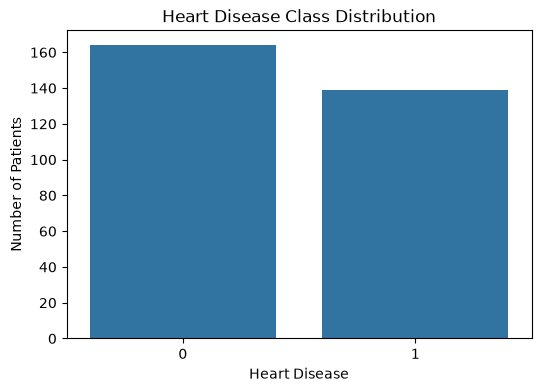

In [12]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="target")

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")

plt.show()

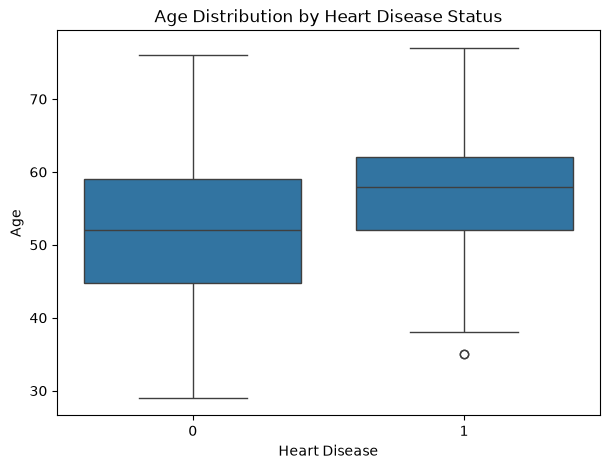

In [13]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="target", y="age")

plt.title("Age Distribution by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Age")

plt.show()

In [14]:
# Feature: AGE

# Observation:
# Disease group tends to be older.

# Potential ML relevance:
# Likely useful predictive feature.

# Action:
# Keep the feature.

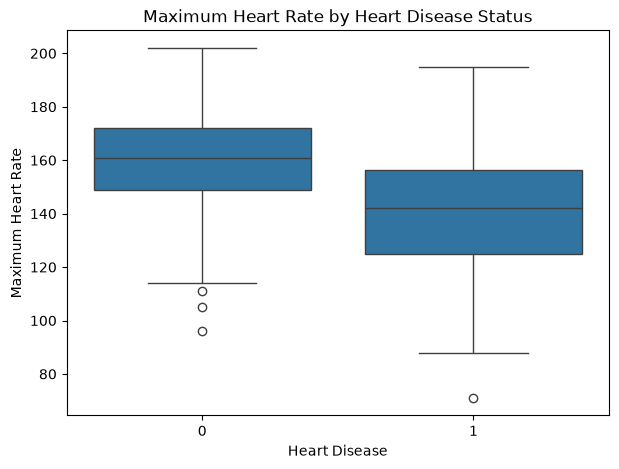

In [15]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="target", y="thalach")

plt.title("Maximum Heart Rate by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Maximum Heart Rate")

plt.show()

In [16]:
#In this dataset, lower maximum achieved heart rate is associated with 
#the heart-disease class and may therefore be a useful predictive feature

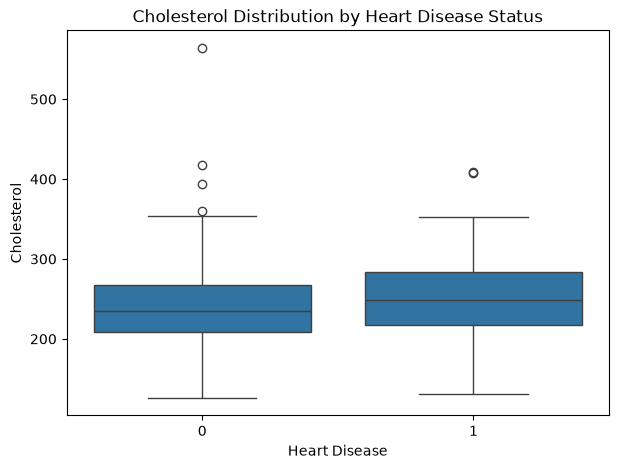

In [17]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="target", y="chol")

plt.title("Cholesterol Distribution by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Cholesterol")

plt.show()

In [18]:
# Groups have very similar/overlapping distributions
#  May be less useful alone

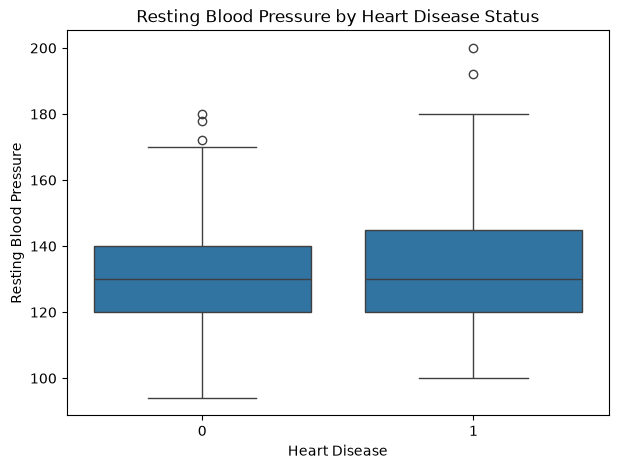

In [19]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="target", y="trestbps")

plt.title("Resting Blood Pressure by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Resting Blood Pressure")

plt.show()

In [20]:
# trestbps doesn't seem to distinguish the 
# classes particularly well on its own

In [21]:
# in chest pain (cp) feature, the values are encoded as follows:

# 1 → Typical angina
# 2 → Atypical angina
# 3 → Non-anginal pain
# 4 → Asymptomatic

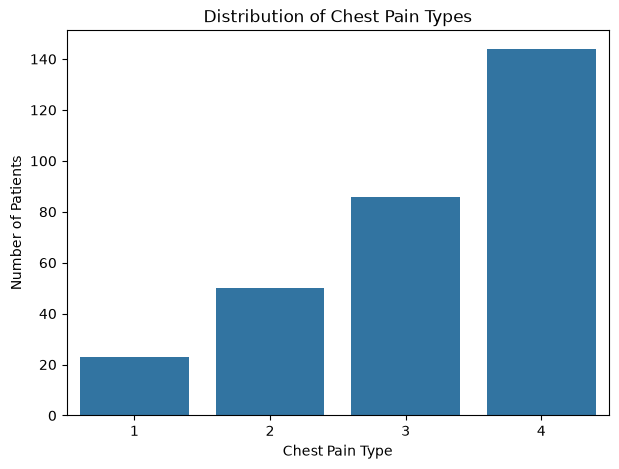

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="cp")

plt.title("Distribution of Chest Pain Types")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")

plt.show()

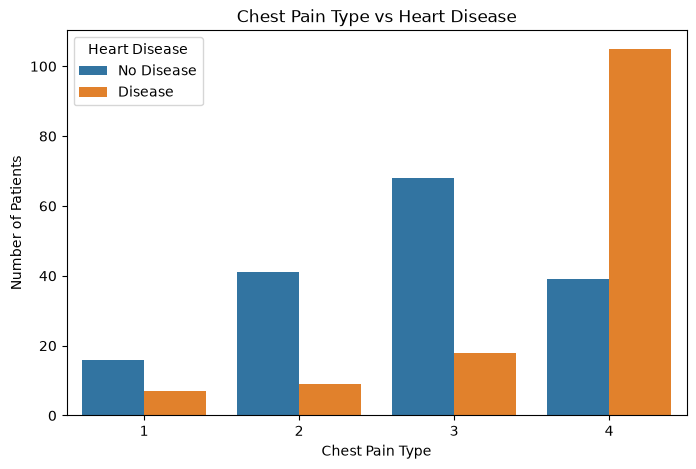

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="cp", hue="target")

plt.title("Chest Pain Type vs Heart Disease")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")
plt.legend(title="Heart Disease", labels=["No Disease", "Disease"])

plt.show()

In [24]:
cp_rate = df.groupby("cp")["target"].mean() * 100

print(cp_rate)

cp
1    30.434783
2    18.000000
3    20.930233
4    72.916667
Name: target, dtype: float64


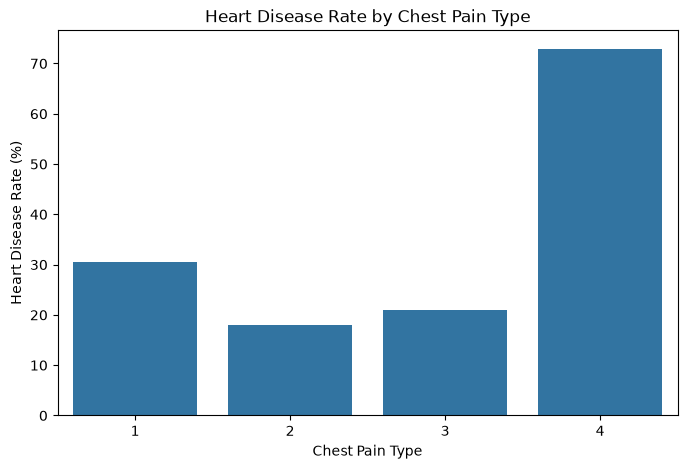

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(x=cp_rate.index, y=cp_rate.values)

plt.title("Heart Disease Rate by Chest Pain Type")
plt.xlabel("Chest Pain Type")
plt.ylabel("Heart Disease Rate (%)")

plt.show()

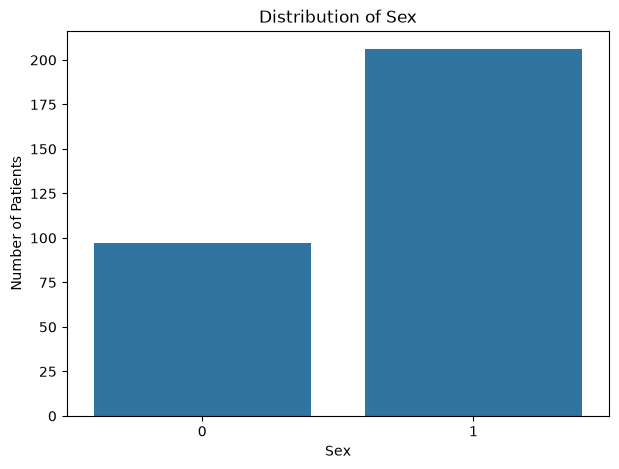

In [26]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex")

plt.title("Distribution of Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Patients")

plt.show()

sex
0    25.773196
1    55.339806
Name: target, dtype: float64


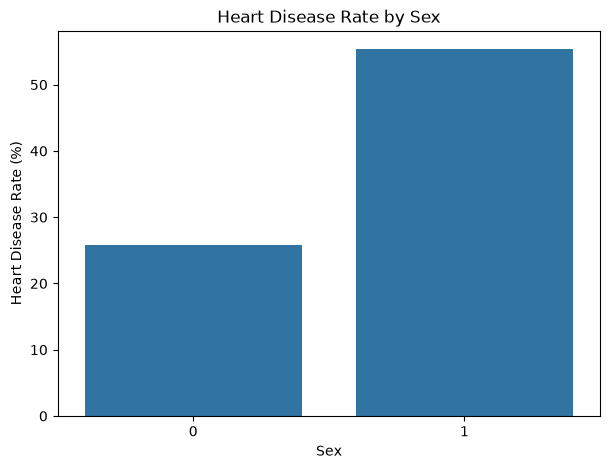

In [27]:
sex_rate = df.groupby("sex")["target"].mean() * 100

print(sex_rate)

plt.figure(figsize=(7, 5))

sns.barplot(x=sex_rate.index, y=sex_rate.values)

plt.title("Heart Disease Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Heart Disease Rate (%)")

plt.show()

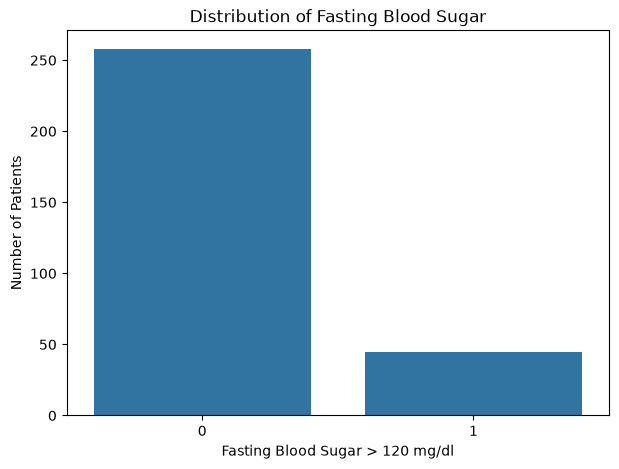

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="fbs")

plt.title("Distribution of Fasting Blood Sugar")
plt.xlabel("Fasting Blood Sugar > 120 mg/dl")
plt.ylabel("Number of Patients")

plt.show()

fbs
0    45.348837
1    48.888889
Name: target, dtype: float64


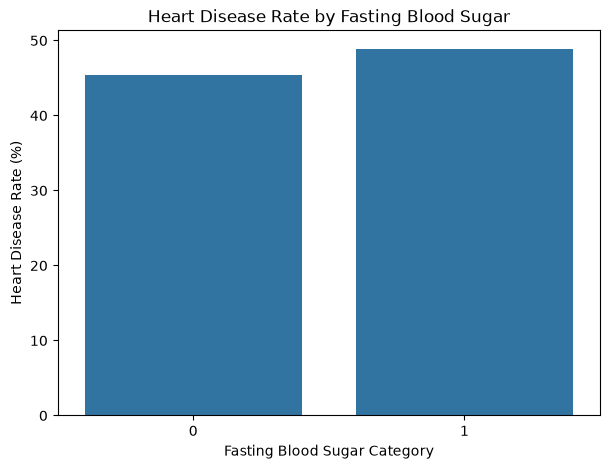

In [29]:
fbs_rate = df.groupby("fbs")["target"].mean() * 100

print(fbs_rate)

plt.figure(figsize=(7, 5))

sns.barplot(x=fbs_rate.index, y=fbs_rate.values)

plt.title("Heart Disease Rate by Fasting Blood Sugar")
plt.xlabel("Fasting Blood Sugar Category")
plt.ylabel("Heart Disease Rate (%)")

plt.show()

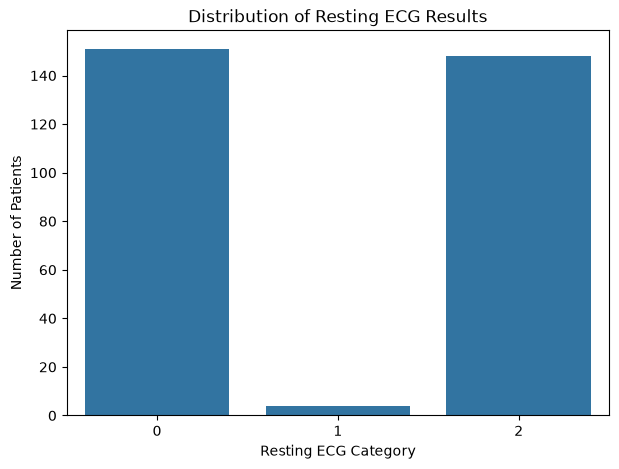

In [30]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="restecg")

plt.title("Distribution of Resting ECG Results")
plt.xlabel("Resting ECG Category")
plt.ylabel("Number of Patients")

plt.show()

In [31]:
restecg_rate = df.groupby("restecg")["target"].mean() * 100

print(restecg_rate)

restecg
0    37.086093
1    75.000000
2    54.054054
Name: target, dtype: float64


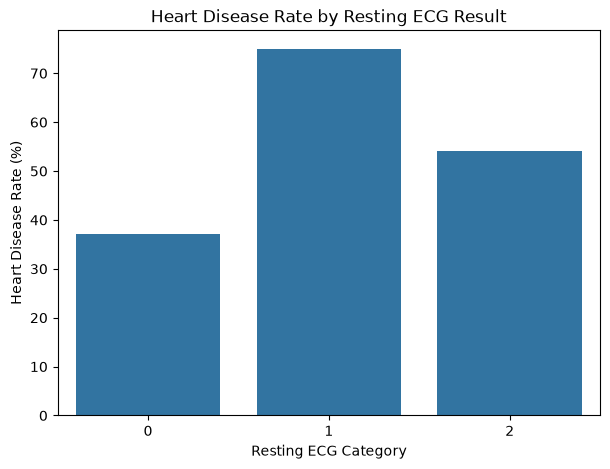

In [32]:
plt.figure(figsize=(7, 5))

sns.barplot(x=restecg_rate.index, y=restecg_rate.values)

plt.title("Heart Disease Rate by Resting ECG Result")
plt.xlabel("Resting ECG Category")
plt.ylabel("Heart Disease Rate (%)")

plt.show()

In [33]:
# restecg = 1 has the highest observed
# heart-disease rate (~75%) in this dataset, suggesting a strong association.
# However, this category contains very few patients, 
# so the estimate may be unreliable and should be interpreted cautiously

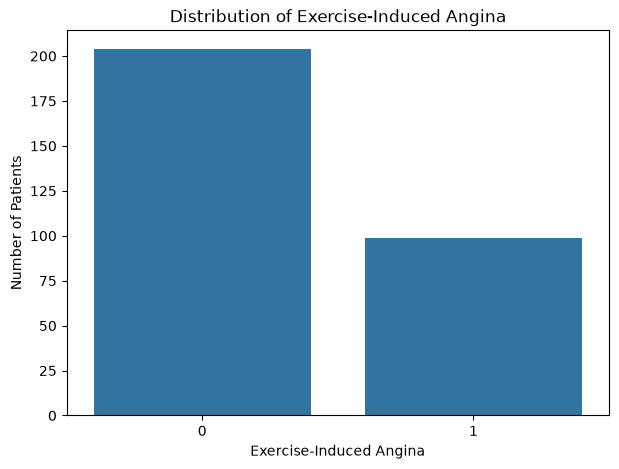

In [34]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="exang")

plt.title("Distribution of Exercise-Induced Angina")
plt.xlabel("Exercise-Induced Angina")
plt.ylabel("Number of Patients")

plt.show()

exang
0    30.882353
1    76.767677
Name: target, dtype: float64


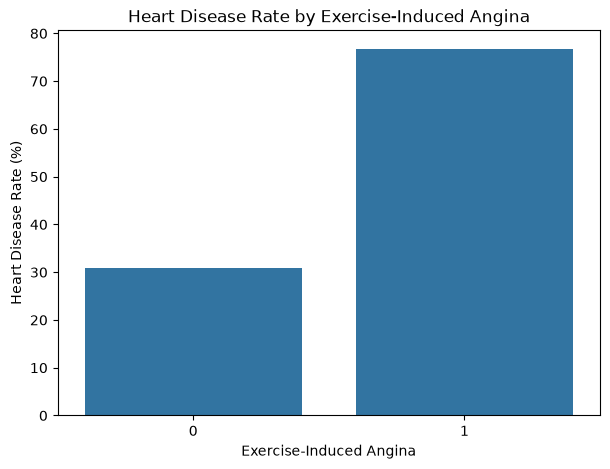

In [35]:
exang_rate = df.groupby("exang")["target"].mean() * 100

print(exang_rate)

plt.figure(figsize=(7, 5))

sns.barplot(x=exang_rate.index, y=exang_rate.values)

plt.title("Heart Disease Rate by Exercise-Induced Angina")
plt.xlabel("Exercise-Induced Angina")
plt.ylabel("Heart Disease Rate (%)")

plt.show()

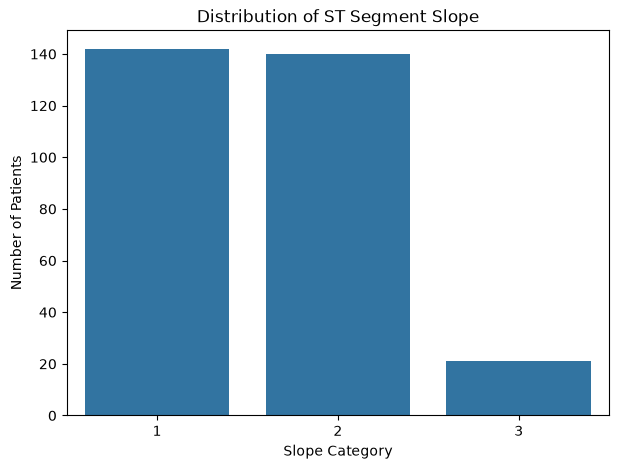

In [36]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="slope")

plt.title("Distribution of ST Segment Slope")
plt.xlabel("Slope Category")
plt.ylabel("Number of Patients")

plt.show()

slope
1    25.352113
2    65.000000
3    57.142857
Name: target, dtype: float64


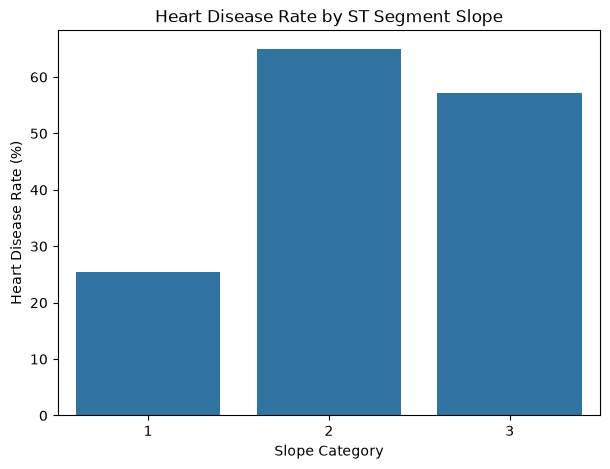

In [37]:
slope_rate = df.groupby("slope")["target"].mean() * 100

print(slope_rate)

plt.figure(figsize=(7, 5))

sns.barplot(x=slope_rate.index, y=slope_rate.values)

plt.title("Heart Disease Rate by ST Segment Slope")
plt.xlabel("Slope Category")
plt.ylabel("Heart Disease Rate (%)")

plt.show()

In [38]:
# One thing to be careful about: your graph labels are 1, 2, 3, even though the
#  original dataset commonly uses 0, 1, 2 for slope. We should check the 
# exact mapping in our dataset before writing the medical meaning into the report. 
# Don't assume the labels are shifted just because the graph starts at 1.

In [39]:
print(df["slope"].value_counts().sort_index())
print(df["thal"].value_counts().sort_index())

slope
1    142
2    140
3     21
Name: count, dtype: int64
thal
3.0    166
6.0     18
7.0    117
Name: count, dtype: int64


In [40]:
thal_rate = df.groupby("thal")["target"].mean() * 100

print(thal_rate)

thal
3.0    22.289157
6.0    66.666667
7.0    76.068376
Name: target, dtype: float64


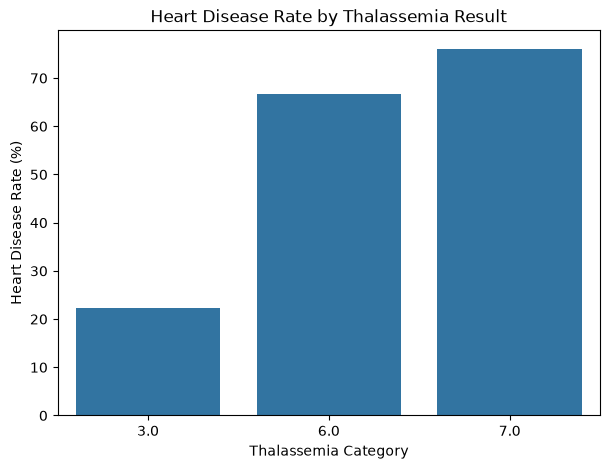

In [41]:
plt.figure(figsize=(7, 5))

sns.barplot(x=thal_rate.index, y=thal_rate.values)

plt.title("Heart Disease Rate by Thalassemia Result")
plt.xlabel("Thalassemia Category")
plt.ylabel("Heart Disease Rate (%)")

plt.show()

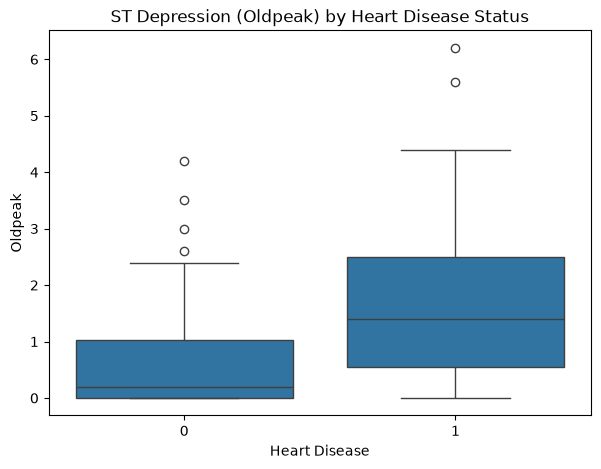

In [42]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="target", y="oldpeak")

plt.title("ST Depression (Oldpeak) by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Oldpeak")

plt.show()

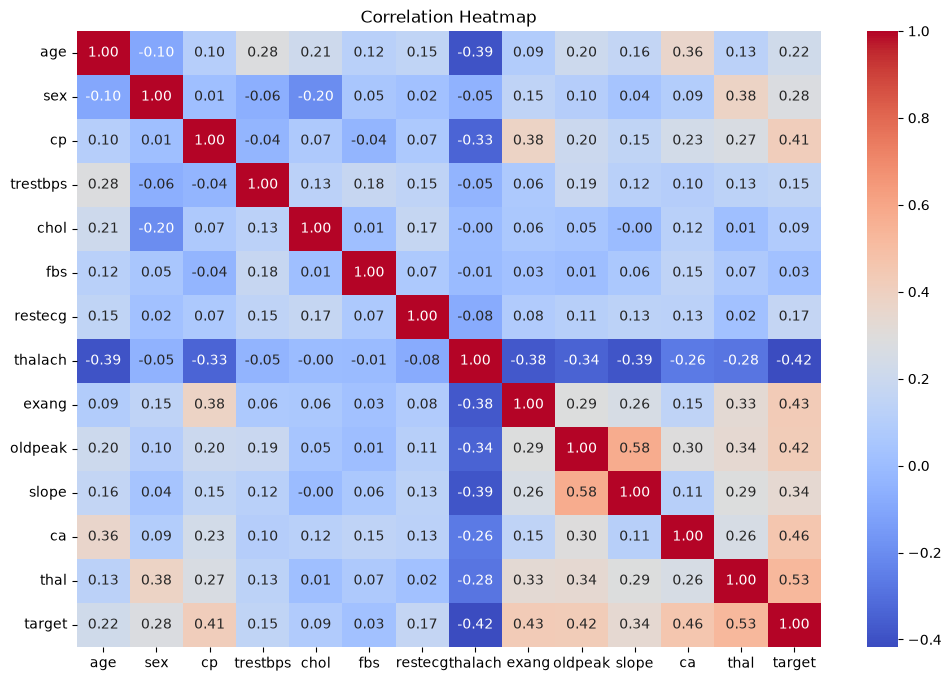

In [43]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [44]:
print(df["ca"].value_counts().sort_index())

ca
0.0    176
1.0     65
2.0     38
3.0     20
Name: count, dtype: int64


In [45]:
ca_rate = df.groupby("ca")["target"].mean() * 100

print(ca_rate)

ca
0.0    26.136364
1.0    67.692308
2.0    81.578947
3.0    85.000000
Name: target, dtype: float64


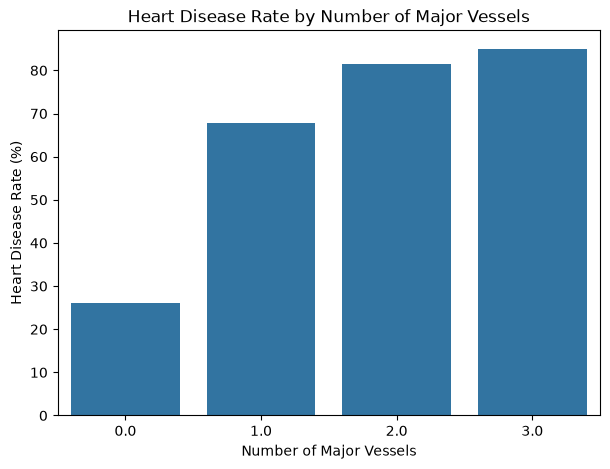

In [46]:
plt.figure(figsize=(7, 5))

sns.barplot(x=ca_rate.index, y=ca_rate.values)

plt.title("Heart Disease Rate by Number of Major Vessels")
plt.xlabel("Number of Major Vessels")
plt.ylabel("Heart Disease Rate (%)")

plt.show()

In [47]:
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True) * 100)

target
0    164
1    139
Name: count, dtype: int64
target
0    54.125413
1    45.874587
Name: proportion, dtype: float64


In [48]:
from sklearn.model_selection import train_test_split

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [49]:
print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training samples: (242, 13)
Testing samples: (61, 13)

Training target distribution:
target
0    54.132231
1    45.867769
Name: proportion, dtype: float64

Testing target distribution:
target
0    54.098361
1    45.901639
Name: proportion, dtype: float64


In [50]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "ca"
]

In [51]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "thal"
]

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [53]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [54]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [55]:
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [56]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [57]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (242, 13)
Processed training shape: (242, 25)
Original testing shape: (61, 13)
Processed testing shape: (61, 25)


In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [59]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [60]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','sex','cp',...,'slope','ca','thal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwe

In [61]:
y_pred = logistic_model.predict(X_test)

In [62]:
y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [63]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.8688524590163934
Precision: 0.8125
Recall   : 0.9285714285714286
F1 Score : 0.8666666666666667
ROC-AUC  : 0.9577922077922079


In [64]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



In [65]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[27  6]
 [ 2 26]]


In [66]:
from sklearn.neighbors import KNeighborsClassifier

In [67]:
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

In [68]:
knn_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','sex','cp',...,'slope','ca','thal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwe

In [69]:
y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

In [70]:
print("KNN Results")
print("Accuracy :", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall   :", recall_score(y_test, y_pred_knn))
print("F1 Score :", f1_score(y_test, y_pred_knn))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_knn))

KNN Results
Accuracy : 0.9016393442622951
Precision: 0.8666666666666667
Recall   : 0.9285714285714286
F1 Score : 0.896551724137931
ROC-AUC  : 0.952922077922078


In [71]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))


Confusion Matrix:
[[29  4]
 [ 2 26]]


In [72]:
k_values = range(1, 21)

knn_accuracy = []
knn_recall = []
knn_roc_auc = []

for k in k_values:

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    knn_accuracy.append(accuracy_score(y_test, predictions))
    knn_recall.append(recall_score(y_test, predictions))
    knn_roc_auc.append(roc_auc_score(y_test, probabilities))

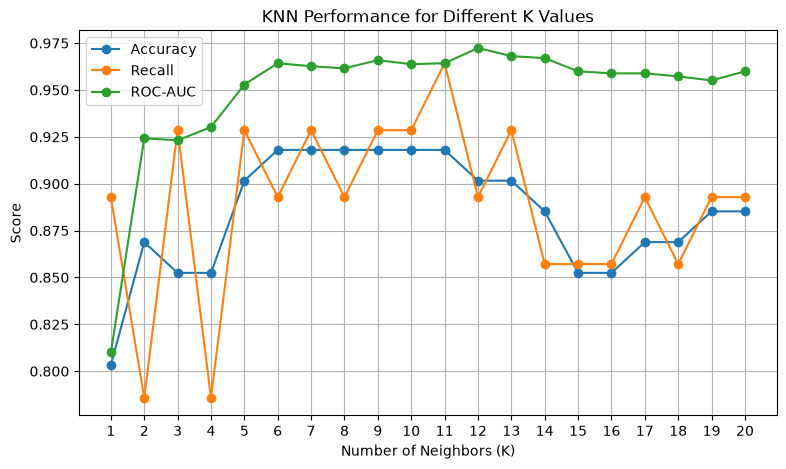

In [73]:
plt.figure(figsize=(9, 5))

plt.plot(k_values, knn_accuracy, marker="o", label="Accuracy")
plt.plot(k_values, knn_recall, marker="o", label="Recall")
plt.plot(k_values, knn_roc_auc, marker="o", label="ROC-AUC")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Score")
plt.title("KNN Performance for Different K Values")

plt.xticks(k_values)
plt.legend()
plt.grid(True)

plt.show()

In [74]:
best_k_accuracy = k_values[np.argmax(knn_accuracy)]
best_k_recall = k_values[np.argmax(knn_recall)]
best_k_auc = k_values[np.argmax(knn_roc_auc)]

print("Best K by Accuracy:", best_k_accuracy)
print("Best K by Recall:", best_k_recall)
print("Best K by ROC-AUC:", best_k_auc)

Best K by Accuracy: 6
Best K by Recall: 11
Best K by ROC-AUC: 12


In [75]:
from sklearn.model_selection import GridSearchCV

In [76]:
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

In [77]:
param_grid = {
    "classifier__n_neighbors": range(1, 21)
}

In [78]:
knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

In [79]:
knn_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': range(1, 21)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during

In [80]:
print("Best K:", knn_grid.best_params_)
print("Best CV ROC-AUC:", knn_grid.best_score_)

Best K: {'classifier__n_neighbors': 20}
Best CV ROC-AUC: 0.883386259473216


In [81]:
best_knn = knn_grid.best_estimator_

y_pred_knn_final = best_knn.predict(X_test)
y_prob_knn_final = best_knn.predict_proba(X_test)[:, 1]

In [82]:
print("Final KNN Results")
print("Accuracy :", accuracy_score(y_test, y_pred_knn_final))
print("Precision:", precision_score(y_test, y_pred_knn_final))
print("Recall   :", recall_score(y_test, y_pred_knn_final))
print("F1 Score :", f1_score(y_test, y_pred_knn_final))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_knn_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn_final))

Final KNN Results
Accuracy : 0.8852459016393442
Precision: 0.8620689655172413
Recall   : 0.8928571428571429
F1 Score : 0.8771929824561403
ROC-AUC  : 0.95995670995671

Confusion Matrix:
[[29  4]
 [ 3 25]]


In [83]:
from sklearn.tree import DecisionTreeClassifier

In [84]:
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

In [85]:
decision_tree.fit(X_train, y_train)
y_pred_tree = decision_tree.predict(X_test)
y_prob_tree = decision_tree.predict_proba(X_test)[:, 1] 
print("Decision Tree Results")
print("Accuracy :", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall   :", recall_score(y_test, y_pred_tree))
print("F1 Score :", f1_score(y_test, y_pred_tree))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_tree))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

Decision Tree Results
Accuracy : 0.7540983606557377
Precision: 0.6857142857142857
Recall   : 0.8571428571428571
F1 Score : 0.7619047619047619
ROC-AUC  : 0.7619047619047621

Confusion Matrix:
[[22 11]
 [ 4 24]]


In [86]:
param_grid = {
    "classifier__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__criterion": ["gini", "entropy"]
}

In [87]:
dt_grid = GridSearchCV(
    estimator=decision_tree,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [2, 3, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... version

In [88]:
print("Best Parameters:")
print(dt_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(dt_grid.best_score_)

Best Parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10}

Best CV ROC-AUC:
0.8324062813193247


In [89]:
best_dt = dt_grid.best_estimator_

y_pred_dt_final = best_dt.predict(X_test)
y_prob_dt_final = best_dt.predict_proba(X_test)[:, 1]

In [90]:
print("Final Decision Tree Results")

print("Accuracy :", accuracy_score(y_test, y_pred_dt_final))
print("Precision:", precision_score(y_test, y_pred_dt_final))
print("Recall   :", recall_score(y_test, y_pred_dt_final))
print("F1 Score :", f1_score(y_test, y_pred_dt_final))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_dt_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt_final))


Final Decision Tree Results
Accuracy : 0.7868852459016393
Precision: 0.7419354838709677
Recall   : 0.8214285714285714
F1 Score : 0.7796610169491526
ROC-AUC  : 0.8728354978354979

Confusion Matrix:
[[25  8]
 [ 5 23]]


In [91]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

In [92]:
rf_param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

In [93]:
rf_grid = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=rf_param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [3, 5, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... ve

In [94]:
print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(rf_grid.best_score_)

Best Random Forest Parameters:
{'classifier__max_depth': 10, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}

Best CV ROC-AUC:
0.9033259011519881


In [95]:
best_rf = rf_grid.best_estimator_

y_pred_rf_final = best_rf.predict(X_test)
y_prob_rf_final = best_rf.predict_proba(X_test)[:, 1]

In [96]:
print("Final Random Forest Results")

print("Accuracy :", accuracy_score(y_test, y_pred_rf_final))
print("Precision:", precision_score(y_test, y_pred_rf_final))
print("Recall   :", recall_score(y_test, y_pred_rf_final))
print("F1 Score :", f1_score(y_test, y_pred_rf_final))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_final))

Final Random Forest Results
Accuracy : 0.8852459016393442
Precision: 0.8387096774193549
Recall   : 0.9285714285714286
F1 Score : 0.8813559322033898
ROC-AUC  : 0.9577922077922079

Confusion Matrix:
[[28  5]
 [ 2 26]]


In [97]:
logistic_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"]
}
logistic_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...], 'classifier__solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the

In [98]:
print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(logistic_grid.best_score_)

Best Logistic Regression Parameters:
{'classifier__C': 1, 'classifier__solver': 'lbfgs'}

Best CV ROC-AUC:
0.8995062103757755


In [99]:
best_logistic = logistic_grid.best_estimator_

y_pred_logistic_final = best_logistic.predict(X_test)
y_prob_logistic_final = best_logistic.predict_proba(X_test)[:, 1]

In [100]:
print("Final Logistic Regression Results")

print("Accuracy :", accuracy_score(y_test, y_pred_logistic_final))
print("Precision:", precision_score(y_test, y_pred_logistic_final))
print("Recall   :", recall_score(y_test, y_pred_logistic_final))
print("F1 Score :", f1_score(y_test, y_pred_logistic_final))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_logistic_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic_final))

Final Logistic Regression Results
Accuracy : 0.8688524590163934
Precision: 0.8125
Recall   : 0.9285714285714286
F1 Score : 0.8666666666666667
ROC-AUC  : 0.9577922077922079

Confusion Matrix:
[[27  6]
 [ 2 26]]


In [101]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic_final),
        accuracy_score(y_test, y_pred_knn_final),
        accuracy_score(y_test, y_pred_dt_final),
        accuracy_score(y_test, y_pred_rf_final)
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic_final),
        precision_score(y_test, y_pred_knn_final),
        precision_score(y_test, y_pred_dt_final),
        precision_score(y_test, y_pred_rf_final)
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic_final),
        recall_score(y_test, y_pred_knn_final),
        recall_score(y_test, y_pred_dt_final),
        recall_score(y_test, y_pred_rf_final)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_logistic_final),
        f1_score(y_test, y_pred_knn_final),
        f1_score(y_test, y_pred_dt_final),
        f1_score(y_test, y_pred_rf_final)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_logistic_final),
        roc_auc_score(y_test, y_prob_knn_final),
        roc_auc_score(y_test, y_prob_dt_final),
        roc_auc_score(y_test, y_prob_rf_final)
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.868852,0.812500,0.928571,0.866667,0.957792
1,KNN,0.885246,0.862069,0.892857,0.877193,0.959957
2,Decision Tree,0.786885,0.741935,0.821429,0.779661,0.872835
3,Random Forest,0.885246,0.838710,0.928571,0.881356,0.957792


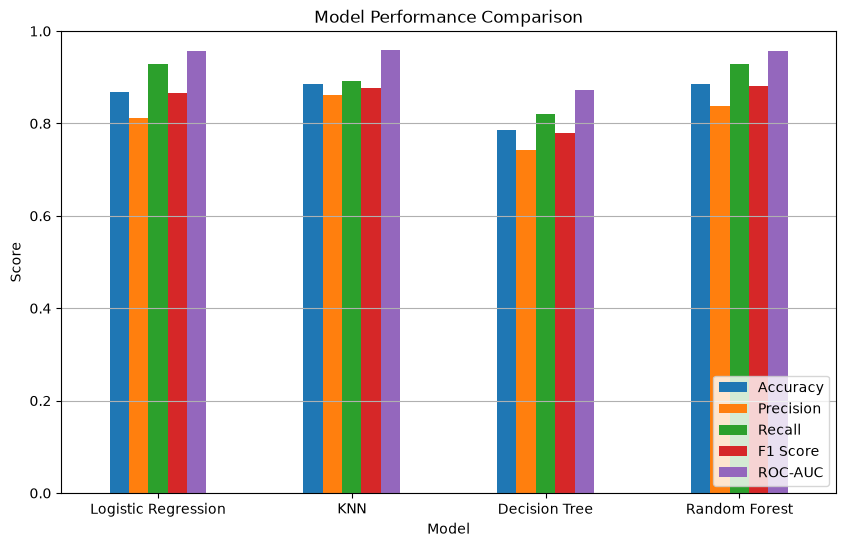

In [102]:
model_results.set_index("Model")[[
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

In [103]:
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()

print("Number of features:", len(feature_names))
print(feature_names)

Number of features: 25
['num__age' 'num__trestbps' 'num__chol' 'num__thalach' 'num__oldpeak'
 'num__ca' 'cat__sex_0.0' 'cat__sex_1.0' 'cat__cp_1.0' 'cat__cp_2.0'
 'cat__cp_3.0' 'cat__cp_4.0' 'cat__fbs_0.0' 'cat__fbs_1.0'
 'cat__restecg_0.0' 'cat__restecg_1.0' 'cat__restecg_2.0' 'cat__exang_0.0'
 'cat__exang_1.0' 'cat__slope_1.0' 'cat__slope_2.0' 'cat__slope_3.0'
 'cat__thal_3.0' 'cat__thal_6.0' 'cat__thal_7.0']


In [104]:
importances = best_rf.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
5,num__ca,0.107713
22,cat__thal_3.0,0.104671
11,cat__cp_4.0,0.096901
3,num__thalach,0.094480
24,cat__thal_7.0,0.093755
4,num__oldpeak,0.076198
17,cat__exang_0.0,0.051485
0,num__age,0.048920
2,num__chol,0.046427
18,cat__exang_1.0,0.040953


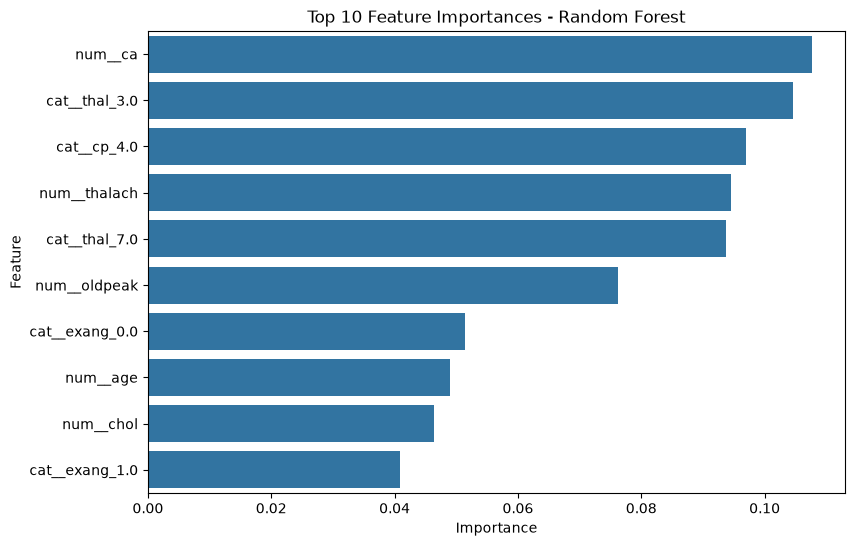

In [105]:
top_features = feature_importance.head(10)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [106]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [107]:
import shap
X_test_processed = best_rf.named_steps["preprocessor"].transform(X_test)

print(X_test_processed.shape)

(61, 25)


In [108]:
rf_model = best_rf.named_steps["classifier"]

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_test_processed)

In [109]:
rf_model = best_rf.named_steps["classifier"]

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_test_processed)

print(type(shap_values))
print(np.shape(shap_values))

<class 'numpy.ndarray'>
(61, 25, 2)


In [110]:
shap_values_class1 = shap_values[:, :, 1]

print(shap_values_class1.shape)

(61, 25)


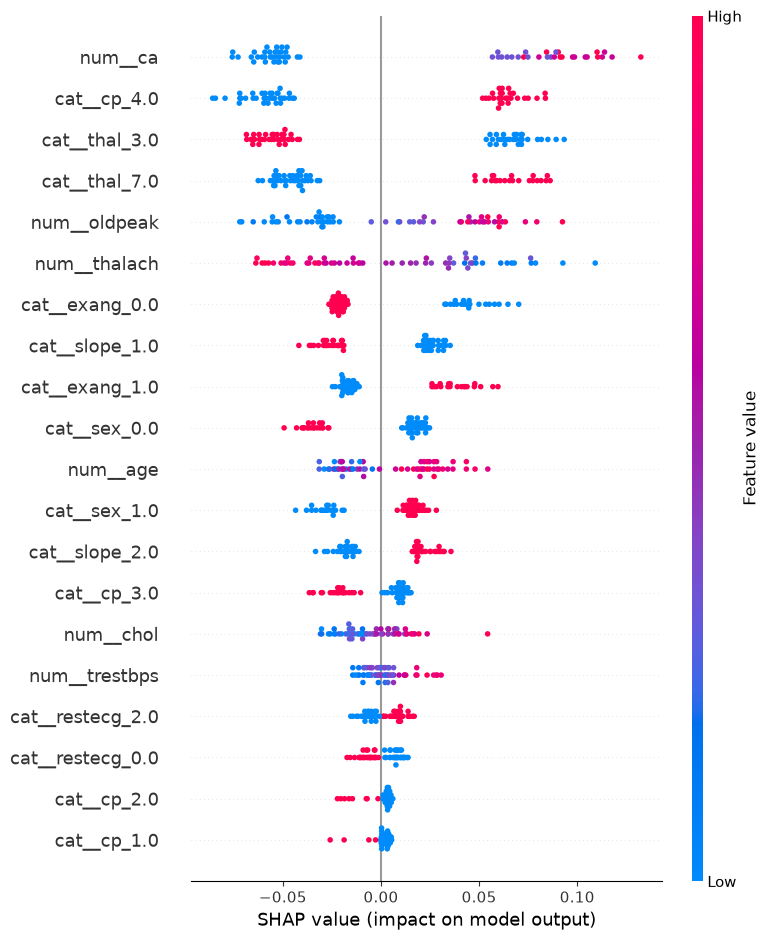

In [111]:
shap.summary_plot(
    shap_values_class1,
    X_test_processed,
    feature_names=feature_names
)

In [112]:
patient_index = 0

patient_data = X_test_processed[patient_index]
patient_shap = shap_values[patient_index, :, 1]

In [113]:
patient_prediction = y_pred_rf_final[patient_index]
patient_probability = y_prob_rf_final[patient_index]

print("Actual:", y_test.iloc[patient_index])
print("Predicted:", patient_prediction)
print("Disease Probability:", patient_probability)

Actual: 0
Predicted: 0
Disease Probability: 0.32896839843163383


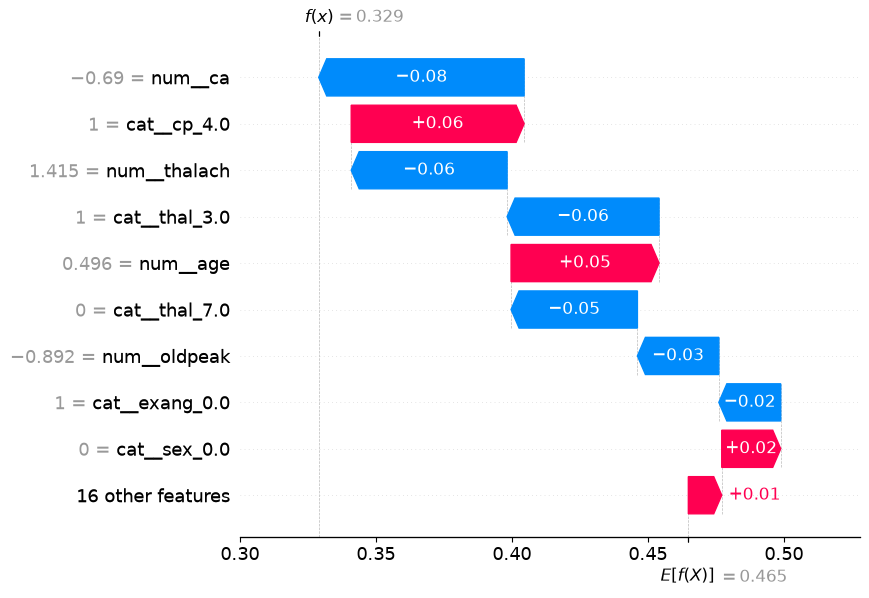

In [114]:
shap_explanation = shap.Explanation(
    values=patient_shap,
    base_values=explainer.expected_value[1],
    data=patient_data,
    feature_names=feature_names
)

shap.plots.waterfall(shap_explanation)

In [115]:
def predict_heart_disease(patient_data):

    patient_df = pd.DataFrame([patient_data])

    prediction = best_rf.predict(patient_df)[0]
    probability = best_rf.predict_proba(patient_df)[0, 1]

    if prediction == 1:
        result = "Heart Disease"
    else:
        result = "No Heart Disease"

    return result, probability

In [116]:
sample_patient = X.iloc[0].to_dict()

result, probability = predict_heart_disease(sample_patient)

print("Prediction:", result)
print("Heart Disease Probability:", round(probability * 100, 2), "%")

Prediction: No Heart Disease
Heart Disease Probability: 31.57 %


In [117]:
import joblib

joblib.dump(best_rf, "heart_disease_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [118]:
import os

print(os.path.exists("heart_disease_model.pkl"))

True
